# Лабораторная №1: "Иерархический кластерный анализ"
## Экономика городов
Шматко Алина  
566321

### Входные данные:
Число наблюдений: 48  
Названия переменных:
* City (Город): Название города
* Work (Работа): Взвешенное среднее числа рабочих часов, сосчитанное по 12 профессиям
* Price (Цена): Индекс цен 112 товаров и услуг, включая арендную плату за жилье (значение для Цюриха взято за 100%)
* Salary (Заработная плата): Индекс заработной платы за час работы, сосчитанный по 12 профессиям после налогов и вычетов (значение для Цюриха взято за 100%)

### Цель работы: 
С помощью иерархического кластерного анализа разбить наблюдения однородные группы на основе их ключевых социально-экономических показателей. Провести анализ полученных кластеров и выявить взаимосвязь между уровнем дохода населения, стоимостью жизни и трудовой нагрузкой в различных регионах мира.


### Подключение библиотек

In [85]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import plotly.express as px

import matplotlib
import matplotlib.pyplot as plt
matplotlib.style.use('ggplot')
%matplotlib inline

from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

### Работа со входными данными

In [86]:
df = pd.read_csv('data/Econom_Cities_data.csv', sep=';', decimal=",", index_col='City')
df.head()

,Work,Price,Salary
City,,,
Amsterdam,1714,65.6,49.0
Athens,1792,53.8,30.4
Bogota,2152,37.9,11.5
Bombay,2052,30.3,5.3
Brussels,1708,73.8,50.5


In [87]:
df

,Work,Price,Salary
City,,,
Amsterdam,1714,65.6,49.0
Athens,1792,53.8,30.4
Bogota,2152,37.9,11.5
Bombay,2052,30.3,5.3
Brussels,1708,73.8,50.5
Buenos_Aires,1971,56.1,12.5
Cairo,-9999,37.1,-9999.0
Caracas,2041,61.0,10.9
Chicago,1924,73.9,61.9


In [88]:
df.shape

(48, 3)

In [89]:
df.dtypes

Work        int64
Price     float64
Salary    float64
dtype: object

Мы видим, что у нас отображется 48 записей  
Столбцы имеют корректную типизацию  
Однако присутствуют некорректные данные, значения которых равняются -9999. Для дальнейшей работы удалим эти неподходящие значения

In [90]:
df[df.isin([-9999]).any(axis=1)]

,Work,Price,Salary
City,,,
Cairo,-9999,37.1,-9999.0
Jakarta,-9999,43.6,-9999.0


In [91]:
df_new = df.replace(-9999, np.nan)
df_new = df_new.dropna()
df_new.shape

(46, 3)

Мы нашли, что только у двух записей есть некорректные данные и после удаления мы получили 46 записей.

### Описательная статистика и построение графиков

In [92]:
df_new.describe()

,Work,Price,Salary
count,46.000000,46.000000,46.000000
mean,1879.913043,70.100000,39.545652
std,174.342552,21.389177,24.757703
min,1583.000000,30.300000,2.700000
25%,1745.250000,51.775000,14.375000
50%,1849.000000,70.950000,43.650000
75%,1976.250000,81.900000,59.700000
max,2375.000000,115.500000,100.000000


Видно, что диапозоны значений заметно отличается между собой. Поэтому перед проведенением иерархического кластерного анализа нам нужно стандартизировать данные

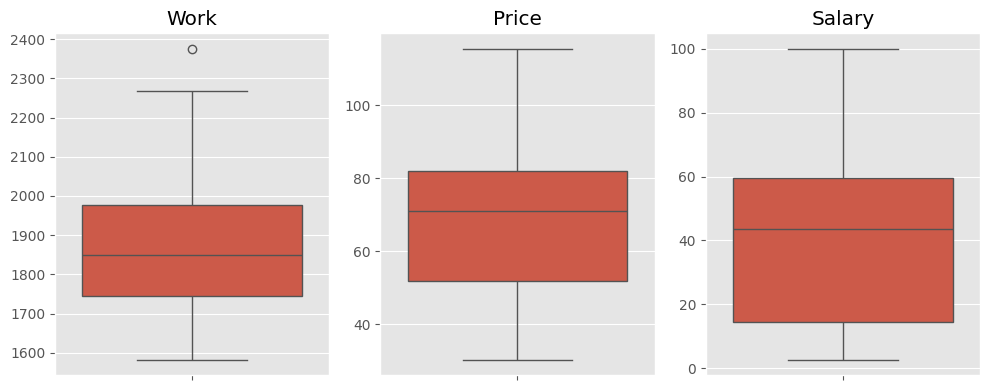

In [93]:
fig, axes = plt.subplots(1, 3, figsize=(10, 4))

for i, var in enumerate(df_new.columns):
    sns.boxplot(y=df_new[var], ax=axes[i])
    axes[i].set_title(var)
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

Видим, что на первом графике есть выброс. Найдем этот город

In [94]:
df_new['Work'].sort_values(ascending=False).head()

City
Hong_Kong       2375.0
Manila          2268.0
Kuala_Lumpur    2167.0
Bogota          2152.0
Taipei          2145.0
Name: Work, dtype: float64

Выбросом на графике является город Hong Kong, однако оснований считать это значение некорректным, либо ошибочным нет

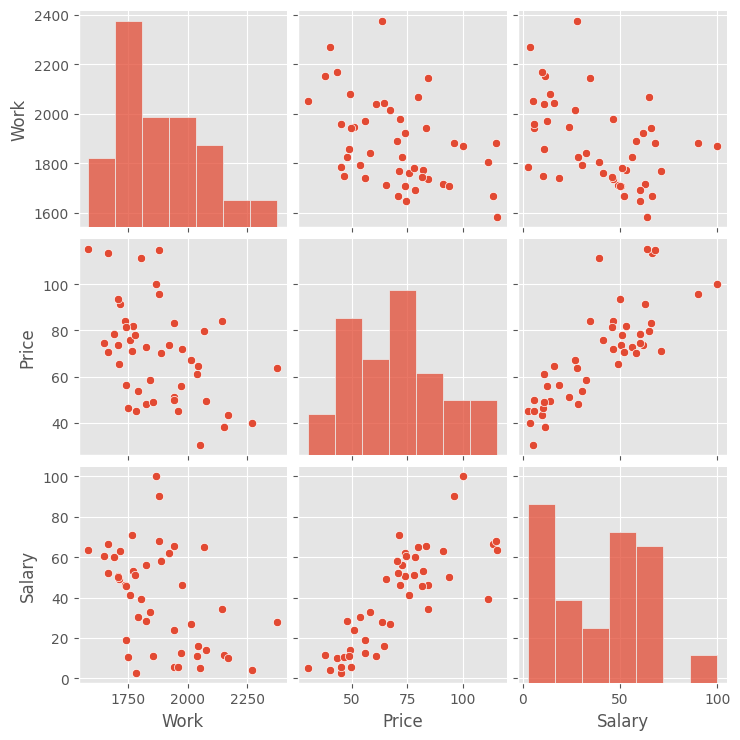

In [95]:
sns.pairplot(df_new)
plt.show()

**гистограммы**\
work: в среднем работают по 1800 часов, онако есть города с высокой нагрузкой \
price: видим два выраженных пика, то есть города в основном разделяются на две группы - дешевая жизнь и дорогая\
salary: также видно два пика - разделение на низкую и высокую зарплату

**графики рассеяния**\
work / salary: больше платят там, где меньше работают и наоборот, где больше работают там меньше платят\
work / price: в городах с большим кол-ом рабочих часов стоимость жизни дешевле\
salary / price: уровень цен линейно связан с уровнем зарплаты  

### Стандартизация данных

Стандартизацию выполним при помощи метода z-core

In [96]:
from sklearn import preprocessing

stand = preprocessing.StandardScaler()
stand.fit(df_new)
X = stand.transform(df_new)
X = pd.DataFrame(X, index=df_new.index, columns=df_new.columns)
X

,Work,Price,Salary
City,,,
Amsterdam,-0.962166,-0.212712,0.386095
Athens,-0.509827,-0.770489,-0.373488
Bogota,1.577891,-1.522069,-1.145323
Bombay,0.997969,-1.881316,-1.398517
Brussels,-0.996961,0.174896,0.447351
Buenos_Aires,0.528233,-0.661769,-1.104485
Caracas,0.934178,-0.430150,-1.169825
Chicago,0.255670,0.179623,0.912902
Copenhagen,-0.944768,1.002108,0.953740


### Кластеризация

Вычислять расстояние между кластерами будем при помщи **метода ward**.  Его ключевая особенность в том, что он минимизирует дисперсию внутри каждой группы. Это позволяет получить максимально компактные, плотные и однородные кластеры.\
А расстояние между точками будем измерять при помощи **евклидового расстояния**, так как оно позволяет оценить, насколько города отличаются друг от друга по всем трём показателям одновременно.

In [97]:
link = linkage(X, 'ward', 'euclidean') 
link

array([[20.        , 33.        ,  0.13000932,  2.        ],
       [26.        , 44.        ,  0.20992596,  2.        ],
       [25.        , 28.        ,  0.24101549,  2.        ],
       [ 6.        , 37.        ,  0.26638013,  2.        ],
       [ 4.        , 39.        ,  0.27962161,  2.        ],
       [ 2.        , 17.        ,  0.28619313,  2.        ],
       [ 7.        , 43.        ,  0.31145704,  2.        ],
       [10.        , 11.        ,  0.31305006,  2.        ],
       [ 1.        , 30.        ,  0.3489377 ,  2.        ],
       [18.        , 34.        ,  0.38756772,  2.        ],
       [ 0.        , 50.        ,  0.419298  ,  3.        ],
       [12.        , 45.        ,  0.44645167,  2.        ],
       [ 9.        , 46.        ,  0.45306282,  3.        ],
       [36.        , 54.        ,  0.4905399 ,  3.        ],
       [13.        , 31.        ,  0.50930475,  2.        ],
       [ 8.        , 23.        ,  0.54142314,  2.        ],
       [ 5.        , 16.

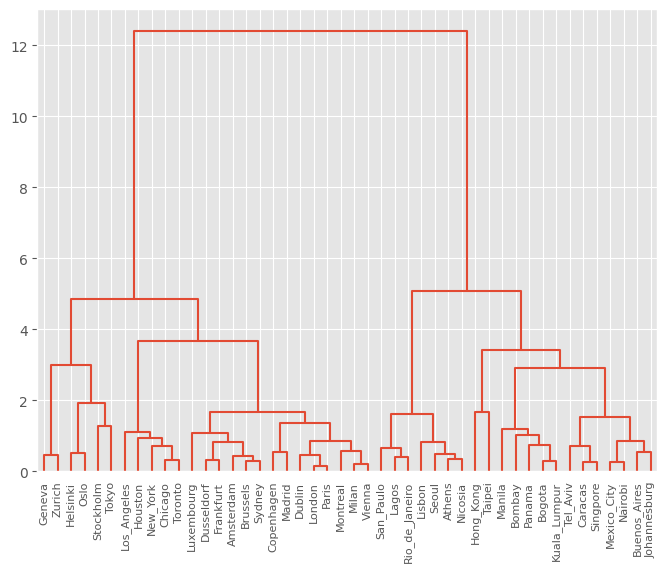

In [98]:
fig = plt.figure(figsize=(8,6))
dn = dendrogram(link, labels = df_new.index.tolist(), color_threshold = -1)

Для обоснования выбора числа кластеров построим график каменистой осыпи

In [99]:
dist = link[:, 2]
dist

array([ 0.13000932,  0.20992596,  0.24101549,  0.26638013,  0.27962161,
        0.28619313,  0.31145704,  0.31305006,  0.3489377 ,  0.38756772,
        0.419298  ,  0.44645167,  0.45306282,  0.4905399 ,  0.50930475,
        0.54142314,  0.54694673,  0.55560294,  0.6525312 ,  0.70695573,
        0.71322146,  0.73106836,  0.80923253,  0.81996004,  0.83440954,
        0.83591396,  0.92010068,  1.00797757,  1.07317494,  1.09798639,
        1.18557963,  1.2661125 ,  1.34552527,  1.5346713 ,  1.60218207,
        1.65009621,  1.67120837,  1.9067302 ,  2.91093293,  2.99369803,
        3.40166518,  3.65965497,  4.85967779,  5.06109685, 12.40027153])

Text(0, 0.5, 'Расстояние')

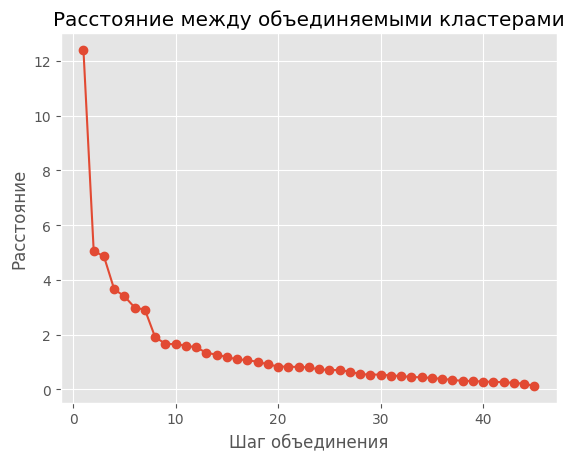

In [100]:
dist_rev = dist[::-1]
idxs = range(1, len(dist) + 1)
plt.plot(idxs, dist_rev, marker='o')
plt.title('Расстояние между объединяемыми кластерами')
plt.xlabel('Шаг объединения')
plt.ylabel('Расстояние')

Рассмотрим подробнее первые 15 шагов, чтобы лучше изучить излом

Text(0, 0.5, 'Расстояние')

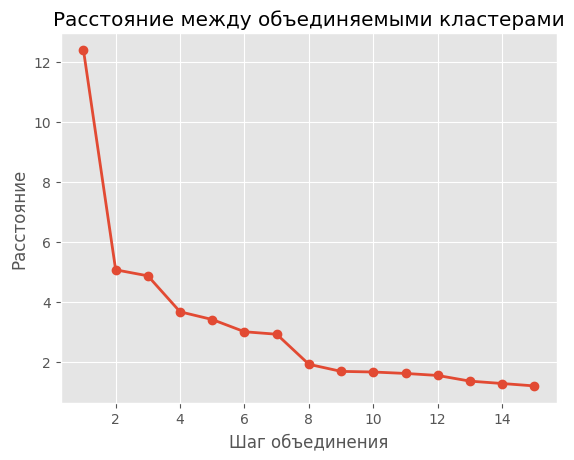

In [101]:
plt.plot(idxs[:15], dist_rev[:15], marker='o', linewidth=2)
plt.title('Расстояние между объединяемыми кластерами')
plt.xlabel('Шаг объединения')
plt.ylabel('Расстояние')

На графики видно, что резкий скачок происходит при переходе от 2 кластеров\
Следующий менее резкий скачок происходит при переходе от 4 кластеров к 3\
На основе этих данных рассмотрим оба варианта группировки: 2 кластера и 4 

### Детальное рассмотрение 2х кластеров

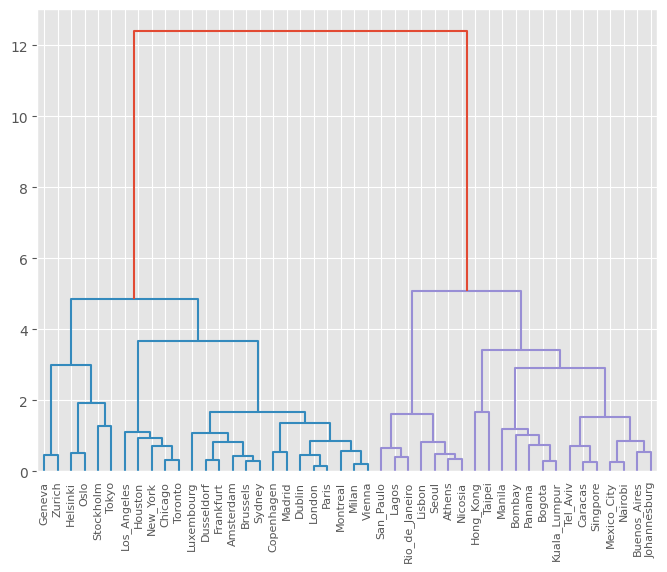

In [102]:
fig = plt.figure(figsize=(8,6))
dn = dendrogram(
    link,
    labels = df_new.index.tolist(),
    color_threshold = 6,
)

In [103]:
df_new['Cluster'] = fcluster(link, 2, criterion='maxclust')
df_new

,Work,Price,Salary,Cluster
City,,,,
Amsterdam,1714.0,65.6,49.0,1
Athens,1792.0,53.8,30.4,2
Bogota,2152.0,37.9,11.5,2
Bombay,2052.0,30.3,5.3,2
Brussels,1708.0,73.8,50.5,1
Buenos_Aires,1971.0,56.1,12.5,2
Caracas,2041.0,61.0,10.9,2
Chicago,1924.0,73.9,61.9,1
Copenhagen,1717.0,91.3,62.9,1


In [104]:
df_new.groupby('Cluster').size()

Cluster
1    25
2    21
dtype: int64

In [105]:
df_new.groupby('Cluster').mean()

,Work,Price,Salary
Cluster,,,
1,1789.240000,84.972000,59.032000
2,1987.857143,52.395238,16.347619


Мы получили разделение на богатых и бедных. Посотрим как это выглядит на графике рассеяния

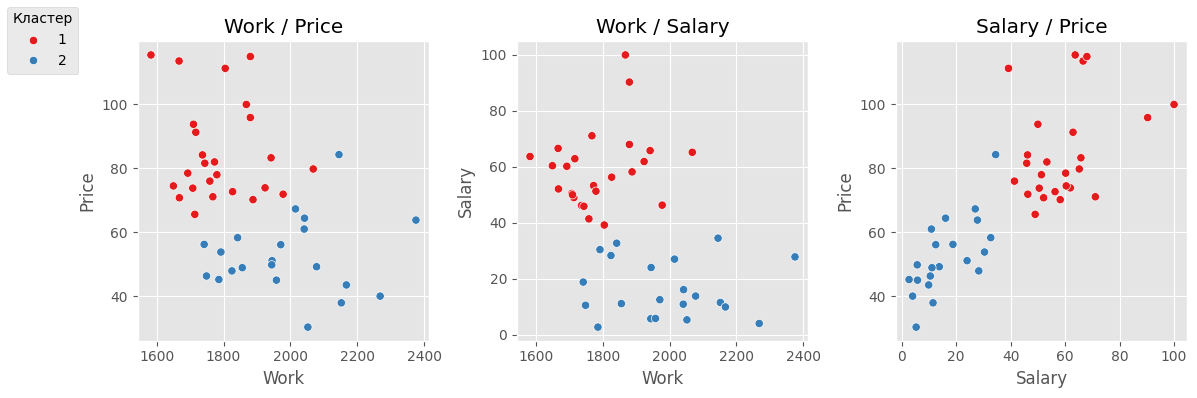

In [106]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

pairs = [
    ('Work', 'Price'),
    ('Work', 'Salary'),
    ('Salary', 'Price')
]

for i, (x, y) in enumerate(pairs):
    sns.scatterplot(
        data = df_new,
        x = x,
        y = y,
        hue = 'Cluster',
        palette = 'Set1',
        ax = axes[i]
    )
    axes[i].set_title(f'{x} / {y}')
    if i == 0:
        handles, labels = axes[i].get_legend_handles_labels()
    axes[i].get_legend().remove()

fig.legend(handles,
    labels,
    title = 'Кластер',
    loc = 'upper left', 
    fontsize = 10)


plt.tight_layout(rect = [0.05, 0, 1, 1])
plt.show()

#### Вывод по 2 кластерам
1 кластер: города с высоким уровнем дохода, высокими ценами и меньшей продолжительностью рабочего дня\
2 кластер: города, жители которого больше работают, но зарплаты и цены низкие

### Детальное изучение 4х кластеров

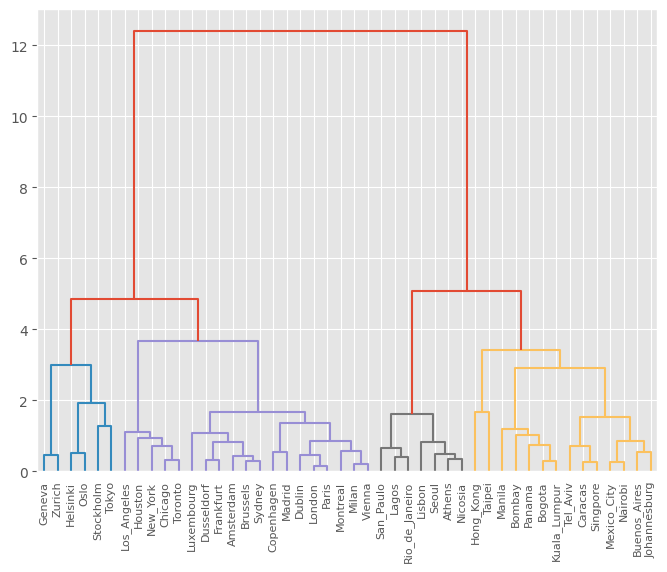

In [107]:
fig2 = plt.figure(figsize=(8,6))
dn2 = dendrogram(
    link,
    labels = df_new.index.tolist(),
    color_threshold = 4,
)

In [108]:
df_new['Cluster'] = fcluster(link, 4, criterion='maxclust')
df_new

,Work,Price,Salary,Cluster
City,,,,
Amsterdam,1714.0,65.6,49.0,2
Athens,1792.0,53.8,30.4,3
Bogota,2152.0,37.9,11.5,4
Bombay,2052.0,30.3,5.3,4
Brussels,1708.0,73.8,50.5,2
Buenos_Aires,1971.0,56.1,12.5,4
Caracas,2041.0,61.0,10.9,4
Chicago,1924.0,73.9,61.9,2
Copenhagen,1717.0,91.3,62.9,2


In [109]:
df_new.groupby('Cluster').size()

Cluster
1     6
2    19
3     7
4    14
dtype: int64

In [110]:
df_new.groupby('Cluster').mean()

,Work,Price,Salary
Cluster,,,
1,1780.500000,108.550000,71.300000
2,1792.000000,77.526316,55.157895
3,1798.857143,50.942857,19.214286
4,2082.357143,53.121429,14.914286


Визулизируем полученные данные для наглядности

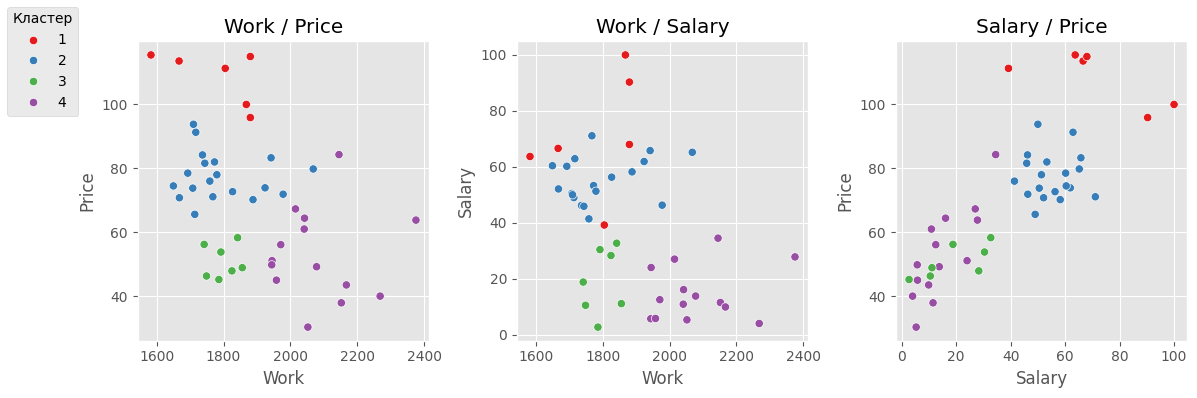

In [111]:
fig2, axes = plt.subplots(1, 3, figsize=(12, 4))

pairs = [
    ('Work', 'Price'),
    ('Work', 'Salary'),
    ('Salary', 'Price')
]

for i, (x, y) in enumerate(pairs):
    sns.scatterplot(
        data = df_new,
        x = x,
        y = y,
        hue = 'Cluster',
        palette = 'Set1',
        ax = axes[i]
    )
    axes[i].set_title(f'{x} / {y}')
    if i == 0:
        handles, labels = axes[i].get_legend_handles_labels()
    axes[i].get_legend().remove()

fig2.legend(handles,
    labels,
    title = 'Кластер',
    loc = 'upper left', 
    fontsize = 10)


plt.tight_layout(rect = [0.05, 0, 1, 1])
plt.show()

Для наглядности и лучшего анализа построим 3D график

In [112]:
df_plot = df_new.reset_index()

# Преобразуем номера кластеров в текст,
# чтобы Plotly отображал их как отдельные категории
df_plot['Cluster'] = df_plot['Cluster'].astype(str)

fig3d = px.scatter_3d(
    df_plot,
    x = 'Work',
    y = 'Salary',
    z = 'Price',
    color = 'Cluster',
    hover_name = 'City',
    title = 'Распределение городов по четырём кластерам',
    color_discrete_sequence = px.colors.qualitative.Set1,
    category_orders={'Cluster': ['1', '2', '3', '4']}
)

fig3d.update_layout(
    width=800,
    height=800,
    scene=dict(
        xaxis_title='Рабочее время (Work)',
        yaxis_title='Зарплата (Salary)',
        zaxis_title='Цены (Price)'
    ),
    legend_title='Кластер'
)

fig3d.update_traces(
    marker=dict(
        size=5
    )
)

fig3d.show()

#### Вывод по 4 кластерам

1 кластер : высокие зарплаты и цены при небольшой нагрузке по работе\
2 кластер: средние значения по всем трем показателям\
3 кластер: города с низкими зарплатами и ценами при умеренной продолжительности рабочего времени\
4 кластер: города с самыми низкими зарплатами и наибольшей продолжительностью рабочего времени. При этом цены лишь немного выше, чем в третьем кластере

### Итоговый вывод

В результате сравнения вариантов разделения на 2 и 4 кластера разбиение на 4 группы позволяет более подробно выделить города со схожими характеристиками и лучше отразить различия между ними. При разделении на 2 кластера группы получаются более обобщёнными, из-за чего некоторые особенности городов остаются незамеченными.